# Project 1: TrivialAugment + Cutout long run

Same model and recipe as `long_run`: post-activation blocks, 64/128/256 channels, 3 blocks per layer (4,327,754 parameters).

**What changed from `long_run`:**
1. Adds TrivialAugment (Müller & Hutter, 2021), which applies one random operation at a random strength to each training image, including brightness, contrast, color and auto-contrast changes.
2. Turns Mixup off. To try TrivialAugment with Mixup, set `mixup_alpha = 0.2`.
3. Epochs go from 160 to 200, because stronger augmentation usually needs longer to converge.
4. Removes EMA and BatchNorm recalibration, because neither helped in `long_run`. This leaves one submission file per run.

**If Colab disconnects, use Run all with the same Config and training resumes from the last checkpoint.**

**Before running:** Runtime → Change runtime type → A100 GPU (T4 also works, but is slower).

## 0. Setup
Put `data.zip` in `MyDrive/dl_proj1/`. It's unzipped to the Colab disk each session, and all outputs are saved back to that Drive folder.

In [1]:
import os, time, zipfile, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, TensorDataset, DataLoader
from torchvision import transforms
from google.colab import drive

drive.mount("/content/drive")
OUT_DIR  = "/content/drive/MyDrive/dl_proj1"     # data.zip lives here; outputs saved here
DATA_DIR = "/content/data"
if not os.path.exists(f"{DATA_DIR}/train_labels.csv"):
    shutil.copy(f"{OUT_DIR}/data.zip", "/content/data.zip")
    zipfile.ZipFile("/content/data.zip").extractall(DATA_DIR)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(NO GPU)")

Mounted at /content/drive
torch 2.14.1+cu130 | device: cuda NVIDIA A100-SXM4-40GB


## 1. Load the images

labeled: (50000, 32, 32, 3) | kaggle test: (2000, 32, 32, 3) | per-class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


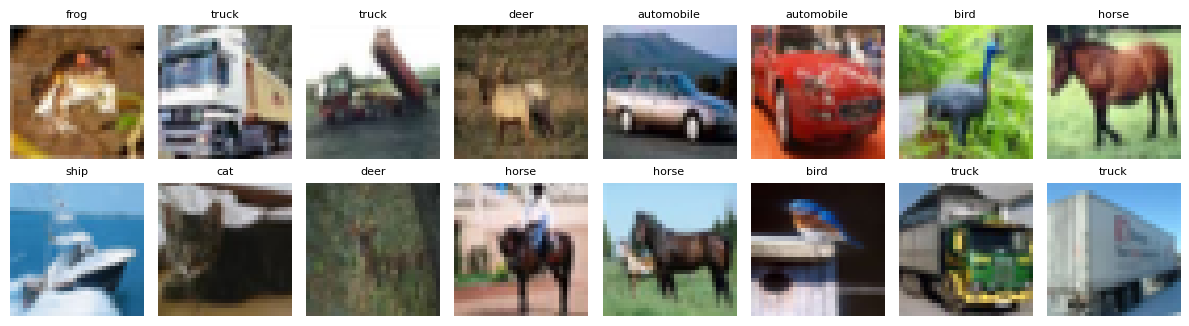

In [2]:
def load_pngs(folder, names):
    return np.stack([np.array(Image.open(f"{folder}/{f}").convert("RGB")) for f in names])

train_df = pd.read_csv(f"{DATA_DIR}/train_labels.csv")
kaggle_test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

cache = f"{OUT_DIR}/cache.npz"               # decoded once (~1 min), then reloaded in seconds
if os.path.exists(cache):
    d = np.load(cache); X_all, y_all, X_kaggle = d["X"], d["y"], d["Xk"]
else:
    X_all    = load_pngs(f"{DATA_DIR}/train_images", train_df.filename)
    y_all    = train_df.label.values.astype(np.int64)
    X_kaggle = load_pngs(f"{DATA_DIR}/test_images", kaggle_test_df.filename)
    np.savez(cache, X=X_all, y=y_all, Xk=X_kaggle)

CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print("labeled:", X_all.shape, "| kaggle test:", X_kaggle.shape, "| per-class:", np.bincount(y_all))

fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i, a in enumerate(ax.flat):
    a.imshow(X_all[i]); a.set_title(CLASSES[y_all[i]], fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

## 2. Config
**Run 1:** `use_all_data = False` (already set). Trains on 40k images and gives validation and local test scores.

**Run 2:** `use_all_data = True`. Trains on all 50k images, with no validation or local test scores.

In [10]:
CONFIG = dict(
    run_name     = "trivial_augment",
    seed         = 0,
    channels     = (64, 128, 256),   # C_i: channels per residual layer
    blocks       = (3, 3, 3),        # B_i: residual blocks per residual layer
    cutout       = 16,               # side of the square that's blanked out; 0 = off
    mixup_alpha  = 0.0,              # 0 = off
    mixup_prob   = 0.5,              # share of batches that get Mixup
    use_all_data = True,            # True = train on all 50k images, with no validation or local test
    checkpoint_every = 5,            # epochs between saves to Drive
    epochs       = 200,
    batch_size   = 128,
    lr           = 0.1,
    momentum     = 0.9,
    weight_decay = 5e-4,
    warmup_epochs = 5,
    min_lr       = 1e-4,
    val_size     = 5000,
    test_size    = 5000,
)
# Include the settings in the name, so each run keeps its own plot, model and submission file
c_name, b_name = "-".join(map(str, CONFIG["channels"])), "-".join(map(str, CONFIG["blocks"]))
CONFIG["run_name"] += f"_c{c_name}_b{b_name}_cut{CONFIG['cutout']}_mix{CONFIG['mixup_alpha']}_ep{CONFIG['epochs']}_bs{CONFIG['batch_size']}"
if CONFIG["use_all_data"]:
    CONFIG.update(val_size=0, test_size=0)
    CONFIG["run_name"] += "_all50k"
torch.manual_seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])

## 3. Train / validation / local-test split, with augmentation
The split is the same as before, and only the training set is augmented. TrivialAugment (Müller & Hutter, 2021) uses `torchvision.transforms.TrivialAugmentWide`. Cutout blanks out a random square of each training image (DeVries & Taylor, 2017). Crop and flip follow [kuangliu/pytorch-cifar](https://github.com/kuangliu/pytorch-cifar).

In [11]:
rng = np.random.default_rng(CONFIG["seed"])
val_idx, test_idx, tr_idx = [], [], []
per_val, per_test = CONFIG["val_size"] // 10, CONFIG["test_size"] // 10
for c in range(10):
    idx = rng.permutation(np.where(y_all == c)[0])
    val_idx += list(idx[:per_val]); test_idx += list(idx[per_val:per_val + per_test]); tr_idx += list(idx[per_val + per_test:])

def to_tensor(x): return torch.tensor(x).permute(0, 3, 1, 2).float() / 255     # NHWC uint8 -> NCHW float

X_tr = to_tensor(X_all[tr_idx])
MEAN, STD = X_tr.mean((0, 2, 3), keepdim=True), X_tr.std((0, 2, 3), keepdim=True)
def prep(x): return (to_tensor(x) - MEAN) / STD

def make_loader(idx, shuffle):
    return DataLoader(TensorDataset(prep(X_all[idx]), torch.tensor(y_all[idx])),
                      batch_size=CONFIG["batch_size"], shuffle=shuffle, pin_memory=(device == "cuda"))

class Cutout:
    def __init__(self, length):
        self.length = length
    def __call__(self, img):                      # img is already normalized, so 0 is the mean color
        y, x = np.random.randint(32), np.random.randint(32)
        y1, y2 = max(0, y - self.length // 2), min(32, y + self.length // 2)
        x1, x2 = max(0, x - self.length // 2), min(32, x + self.length // 2)
        img[:, y1:y2, x1:x2] = 0
        return img

tf_list = [transforms.ToPILImage(), transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(), transforms.TrivialAugmentWide()]
tf_list += [transforms.ToTensor(), transforms.Normalize(MEAN.flatten().tolist(), STD.flatten().tolist())]
if CONFIG["cutout"] > 0:
    tf_list.append(Cutout(CONFIG["cutout"]))
train_tf = transforms.Compose(tf_list)

class AugmentedTrainSet(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])

train_loader = DataLoader(AugmentedTrainSet(X_all[tr_idx], y_all[tr_idx], train_tf), batch_size=CONFIG["batch_size"],
                          shuffle=True, num_workers=min(4, os.cpu_count()), persistent_workers=True, pin_memory=(device == "cuda"))
val_loader   = make_loader(val_idx, shuffle=False)
test_loader  = make_loader(test_idx, shuffle=False)
del X_tr
print(f"train {len(tr_idx)} | val {len(val_idx)} | local test {len(test_idx)}")
print("mean", MEAN.flatten().numpy().round(4), "std", STD.flatten().numpy().round(4))

train 50000 | val 0 | local test 0
mean [0.4914 0.4822 0.4465] std [0.247  0.2435 0.2616]


## 4. Model
A residual block computes `ReLU(S(x) + F(x))`, where F = conv3×3 → BN → ReLU → conv3×3 → BN. S is the identity, or a 1×1 conv + BN when the stride or channel count changes.

In [12]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Sequential()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, channels, blocks, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False), nn.BatchNorm2d(channels[0]), nn.ReLU())
        layers, cin = [], channels[0]
        for i, (c, b) in enumerate(zip(channels, blocks)):
            for j in range(b):
                layers.append(BasicBlock(cin, c, 2 if (i > 0 and j == 0) else 1))   # downsample at start of layers 2, 3, ...
                cin = c
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(cin, num_classes)

    def forward(self, x):
        x = self.layers(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(x)

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

model = ResNet(CONFIG["channels"], CONFIG["blocks"]).to(device)
n_params = count_params(model)
print(model)
print(f"\nTrainable parameters: {n_params:,}")
assert n_params <= 5_000_000, "Over the 5M parameter limit!"

ResNet(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (layers): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), paddi

## 5. Train
Same recipe as `long_run`. The checkpoint holds everything needed to continue. If training has already finished, rerunning this cell skips straight to the results.

In [13]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(model.parameters(), lr=CONFIG["lr"], momentum=CONFIG["momentum"], weight_decay=CONFIG["weight_decay"])

warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=CONFIG["warmup_epochs"])
cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"] - CONFIG["warmup_epochs"], eta_min=CONFIG["min_lr"])
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[CONFIG["warmup_epochs"]])

use_amp = device == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, train):
    model.train(train); total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            use_mixup = train and CONFIG["mixup_alpha"] > 0 and np.random.rand() < CONFIG["mixup_prob"]
            if use_mixup:
                lam = np.random.beta(CONFIG["mixup_alpha"], CONFIG["mixup_alpha"])
                perm = torch.randperm(len(xb), device=device)
                xb = lam * xb + (1 - lam) * xb[perm]
            with torch.autocast("cuda", enabled=use_amp):
                out = model(xb)
                loss = lam * criterion(out, yb) + (1 - lam) * criterion(out, yb[perm]) if use_mixup else criterion(out, yb)
            if train:
                optimizer.zero_grad()
                scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            total_loss += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    if n == 0: return float("nan"), float("nan")      # no validation set when use_all_data = True
    return total_loss / n, correct / n

hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
start_epoch, minutes_before = 0, 0.0
ckpt_path = f"{OUT_DIR}/checkpoint_{CONFIG['run_name']}.pt"
if os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"]); scheduler.load_state_dict(ckpt["scheduler"]); scaler.load_state_dict(ckpt["scaler"])
    hist, start_epoch, minutes_before = ckpt["hist"], ckpt["epoch"], ckpt["minutes"]
    print(f"Resuming from epoch {start_epoch}")

t0 = time.time()
for ep in range(start_epoch, CONFIG["epochs"]):
    lr_now = optimizer.param_groups[0]["lr"]
    tl, ta = run_epoch(train_loader, train=True)
    vl, va = run_epoch(val_loader, train=False)
    for k, v in zip(hist, [tl, ta, vl, va]): hist[k].append(v)
    scheduler.step()
    print(f"epoch {ep+1:2d}/{CONFIG['epochs']} | lr {lr_now:.5f} | train loss {tl:.3f} acc {ta*100:5.2f}% | val loss {vl:.3f} acc {va*100:5.2f}% | {time.time()-t0:4.0f}s")
    if (ep + 1) % CONFIG["checkpoint_every"] == 0 or ep + 1 == CONFIG["epochs"]:
        torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                    "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "hist": hist,
                    "epoch": ep + 1, "minutes": minutes_before + (time.time() - t0) / 60}, ckpt_path)
train_minutes = minutes_before + (time.time() - t0) / 60

epoch  1/200 | lr 0.01000 | train loss 1.906 acc 29.56% | val loss nan acc   nan% |   10s
epoch  2/200 | lr 0.02800 | train loss 1.680 acc 39.30% | val loss nan acc   nan% |   19s
epoch  3/200 | lr 0.04600 | train loss 1.507 acc 45.92% | val loss nan acc   nan% |   29s
epoch  4/200 | lr 0.06400 | train loss 1.365 acc 51.56% | val loss nan acc   nan% |   39s
epoch  5/200 | lr 0.08200 | train loss 1.262 acc 55.15% | val loss nan acc   nan% |   48s
epoch  6/200 | lr 0.10000 | train loss 1.202 acc 57.45% | val loss nan acc   nan% |   58s
epoch  7/200 | lr 0.09999 | train loss 1.133 acc 60.07% | val loss nan acc   nan% |   68s
epoch  8/200 | lr 0.09997 | train loss 1.085 acc 61.95% | val loss nan acc   nan% |   77s
epoch  9/200 | lr 0.09994 | train loss 1.063 acc 62.82% | val loss nan acc   nan% |   87s
epoch 10/200 | lr 0.09990 | train loss 1.036 acc 63.63% | val loss nan acc   nan% |   97s
epoch 11/200 | lr 0.09984 | train loss 1.016 acc 64.57% | val loss nan acc   nan% |  106s
epoch 12/2

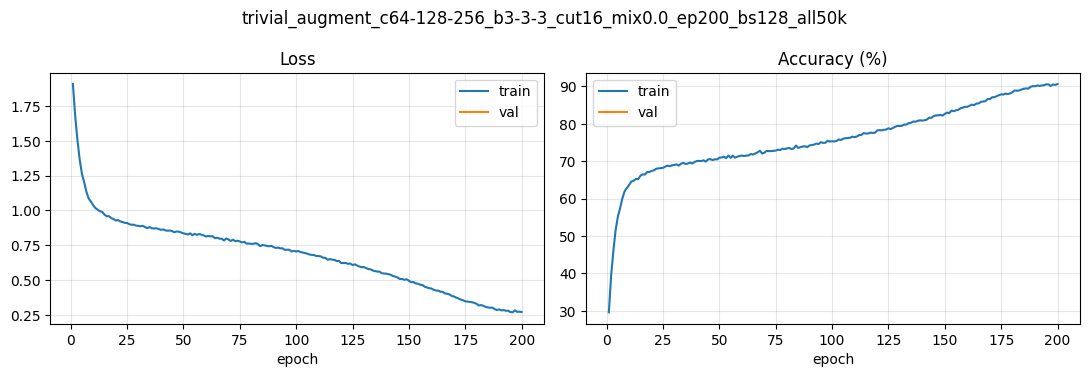

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
epochs = range(1, CONFIG["epochs"] + 1)
ax[0].plot(epochs, hist["train_loss"], label="train"); ax[0].plot(epochs, hist["val_loss"], label="val"); ax[0].set_title("Loss")
ax[1].plot(epochs, [a*100 for a in hist["train_acc"]], label="train"); ax[1].plot(epochs, [a*100 for a in hist["val_acc"]], label="val"); ax[1].set_title("Accuracy (%)")
for a in ax: a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
plt.suptitle(CONFIG["run_name"]); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves_{CONFIG['run_name']}.png", dpi=120); plt.show()

## 6. Final accuracy
Scored with and without flip TTA.

In [15]:
def predict_flip_tta(net, x):                     # average of the predictions for x and its mirror image
    with torch.autocast("cuda", enabled=use_amp):
        return (net(x).softmax(1) + net(x.flip(3)).softmax(1)).argmax(1)

def accuracy(net, loader, tta):
    correct, n = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            with torch.autocast("cuda", enabled=use_amp):
                preds = predict_flip_tta(net, xb) if tta else net(xb).argmax(1)
            correct += (preds.cpu() == yb).sum().item(); n += len(yb)
    return correct / n if n else float("nan")

model.eval()
scores = {"val": accuracy(model, val_loader, False), "val_tta": accuracy(model, val_loader, True),
          "test": accuracy(model, test_loader, False), "test_tta": accuracy(model, test_loader, True)}

print("=" * 60)
print(f"Run:                  {CONFIG['run_name']}")
print(f"Trainable parameters: {n_params:,}")
print(f"Training time:        {train_minutes:.1f} min\n")
for name, value in scores.items(): print(f"{name:9s} {value*100:.2f}%")
print("=" * 60)

Run:                  trivial_augment_c64-128-256_b3-3-3_cut16_mix0.0_ep200_bs128_all50k
Trainable parameters: 4,327,754
Training time:        32.1 min

val       nan%
val_tta   nan%
test      nan%
test_tta  nan%


## 7. Log the run and save outputs
Each run appends one row to `experiments.csv`. Its `val_acc` and `local_test_acc` columns are without TTA, and the TTA scores are at the end of its `config` column.

One submission file with flip TTA is saved: `submission_<run_name>_tta.csv`.

In [16]:
torch.save(model.state_dict(), f"{OUT_DIR}/model_{CONFIG['run_name']}.pt")

log_path = f"{OUT_DIR}/experiments.csv"
row = {"run_name": CONFIG["run_name"], "params": n_params, "epochs": CONFIG["epochs"],
       "val_acc": round(scores["val"], 4), "local_test_acc": round(scores["test"], 4),
       "minutes": round(train_minutes, 1), "config": str({**CONFIG, "scores": scores}), "kaggle_acc": ""}
pd.DataFrame([row]).to_csv(log_path, mode="a", header=not os.path.exists(log_path), index=False)
print(pd.read_csv(log_path)[["run_name", "params", "val_acc", "local_test_acc", "minutes", "kaggle_acc"]].to_string(index=False))

# Kaggle submission file, with flip TTA
X_k = prep(X_kaggle)
with torch.no_grad():
    preds = [predict_flip_tta(model, X_k[k:k+500].to(device)).cpu() for k in range(0, len(X_k), 500)]
sub = pd.DataFrame({"id": kaggle_test_df.id, "label": torch.cat(preds).numpy()})
sub_path = f"{OUT_DIR}/submission_{CONFIG['run_name']}_tta.csv"
sub.to_csv(sub_path, index=False)
print(f"Saved {sub_path}  (predicted class counts {np.bincount(sub.label, minlength=10)})")

                                                                  run_name  params  val_acc  local_test_acc  minutes  kaggle_acc
                                                            step1_baseline 2777674   0.8450          0.8580      9.5         NaN
                                               crop_flip_lr0.01_ep30_bs128 2777674   0.8706          0.8746     18.5         NaN
                  optimizer_scheduler_sgd_cosine_lr0.1_wd0.0005_ep30_bs128 2777674   0.9232          0.9294     18.1         NaN
               optimizer_scheduler_adam_cosine_lr0.001_wd0.0001_ep30_bs128 2777674   0.9136          0.9156     17.7         NaN
            optimizer_scheduler_rmsprop_cosine_lr0.001_wd0.0001_ep30_bs128 2777674   0.9094          0.9134     17.9         NaN
                         architecture_preact_c64-128-256_b3-3-3_ep30_bs128 4298970   0.9266          0.9346     10.7         NaN
                           architecture_post_c64-128-256_b3-3-3_ep30_bs128 4327754   0.9330      